<a href="https://colab.research.google.com/github/sonaliliyanahetti/AI_Fundamentals/blob/main/Markov_Decision_Process_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Markov Decision Process (MDP)

### Ransalu Senanayake

In [ ]:
import copy
import timeit
import numpy as np
import matplotlib.pyplot as pl
%matplotlib inline
from ipywidgets import interactive
import ipywidgets as widgets

Create the following grid world.

**States:** A 10x10 grid

**Actions:** Up, Down, Left, Right

**Tranistion probabilities:**
* 0.7 in the direction of action
* 0.1 in the three other directions
* The robot bounces back to the same state near edges

**Rewards:**
* (7,8) has a reward +10
* (2,7) has a reward +3
* (4,3) has a reward -5
* (7,3) has a reward -10
* No reward in other states

This example is based on Decision Making Under Uncertainty by M.J. Kochenderfer.

In [ ]:
#Let's define MDP paras
def createGrid10World():
    def xy2s(y, x):
        x = max(x, 0)
        y = max(y, 0)
        x = min(x, 9)
        y = min(y, 9)
        out = np.ravel_multi_index(np.array([x,y]), (10,10))
        return out

    def s2xy(s):
        x, y = np.unravel_index(s, (10,10))
        return y, x

    def gridPlot(ax, im, title='', cmap='Blues'):
        pl.imshow(im, interpolation='none', cmap=cmap, origin='lower')
        pl.colorbar()
        ax.set_xticks(np.arange(0, 10, 1));
        ax.set_yticks(np.arange(0, 10, 1));
        ax.set_xticklabels(np.arange(0, 10, 1));
        ax.set_yticklabels(np.arange(0, 10, 1));
        ax.set_xticks(np.arange(-.5, 10, 1), minor=True);
        ax.set_yticks(np.arange(-.5, 10, 1), minor=True);
        ax.grid(which='minor', color='w', linestyle='-', linewidth=1)
        pl.title(title);
        return

    A = ['left', 'right', 'up', 'down']
    S = np.arange(100)
    T = np.zeros((len(S), len(A), len(S)))
    R = np.zeros((len(S), len(A)))
    for s in S:
        x, y = s2xy(s)
        if x == 2 and y == 7:
            R[s, :] = 3
        elif x == 7 and y == 8:
            R[s, :] = 10
        else:
            if x == 7 and y == 3:
                R[s, :] = -10
            elif x == 4 and y == 3:
                R[s, :] = -5
            elif x == 0:
                if y == 0 or y == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 0] = -0.7
            elif x == 9:
                if y == 0 or y == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 1] = -0.7
            elif y == 0:
                if x == 0 or x == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 3] = -0.7
            elif y == 9:
                if x == 0 or x == 9:
                    R[s, :] = -0.2
                else:
                    R[s, :] = -0.1
                R[s, 2] = -0.7

            for a in A:
                if a == 'left':
                    T[s, 0, xy2s(x - 1, y)] += 0.7
                    T[s, 0, xy2s(x + 1, y)] += 0.1
                    T[s, 0, xy2s(x, y - 1)] += 0.1
                    T[s, 0, xy2s(x, y + 1)] += 0.1
                elif a == 'right':
                    T[s, 1, xy2s(x + 1, y)] += 0.7
                    T[s, 1, xy2s(x - 1, y)] += 0.1
                    T[s, 1, xy2s(x, y - 1)] += 0.1
                    T[s, 1, xy2s(x, y + 1)] += 0.1
                elif a == 'up':
                    T[s, 2, xy2s(x, y + 1)] += 0.7
                    T[s, 2, xy2s(x, y - 1)] += 0.1
                    T[s, 2, xy2s(x - 1, y)] += 0.1
                    T[s, 2, xy2s(x + 1, y)] += 0.1
                elif a == 'down':
                    T[s, 3, xy2s(x, y - 1)] += 0.7
                    T[s, 3, xy2s(x, y + 1)] += 0.1
                    T[s, 3, xy2s(x - 1, y)] += 0.1
                    T[s, 3, xy2s(x + 1, y)] += 0.1

    for a, c_x, c_y in [(0,0,0), (0,0,9),(1,9,0),(1,9,9),(2,0,9),(2,9,9),(3,0,0),(3,9,0)]:
        R[xy2s(c_x,c_y),a] = -0.8

    discount = 0.9

    nextStates = {}
    for si in range(len(S)):
        for ai in range(len(A)):
            nextStates[(si,ai)] = np.where((T[si, ai, :] != 0) == True)[0]

    return {'S':S, 'A':A, 'T':T, 'R':R, 'discount':discount, 'nextStates':nextStates, 'gridPlot':gridPlot, 'xy2s':xy2s, 's2xy':s2xy}

In [ ]:
class MDP():
    def __init__(self):
        pass

    def inbuilt_init(self, mdp_dict):
        self.S = mdp_dict['S']
        self.A = mdp_dict['A']
        self.T = mdp_dict['T']
        self.R = mdp_dict['R']
        self.discount = mdp_dict['discount']
        self.nextStates = mdp_dict['nextStates']
        self.gridPlot = mdp_dict['gridPlot']
        self.xy2s = mdp_dict['xy2s']
        self.s2xy = mdp_dict['s2xy']

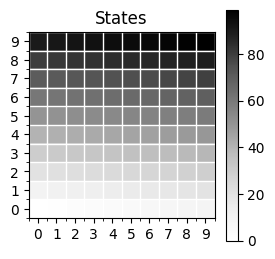

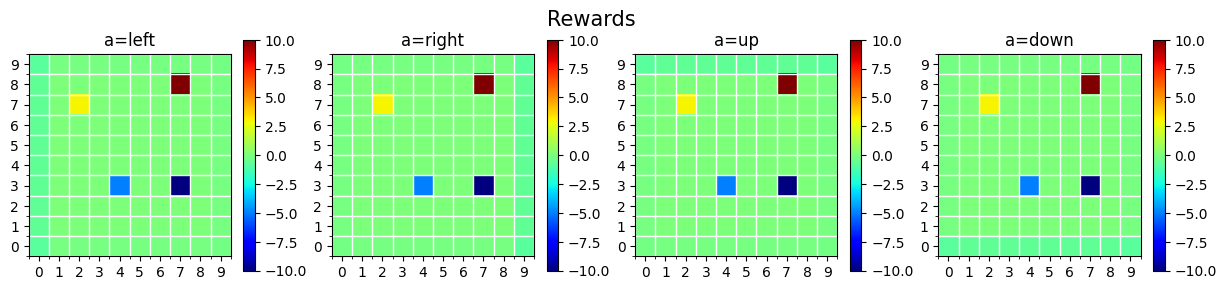

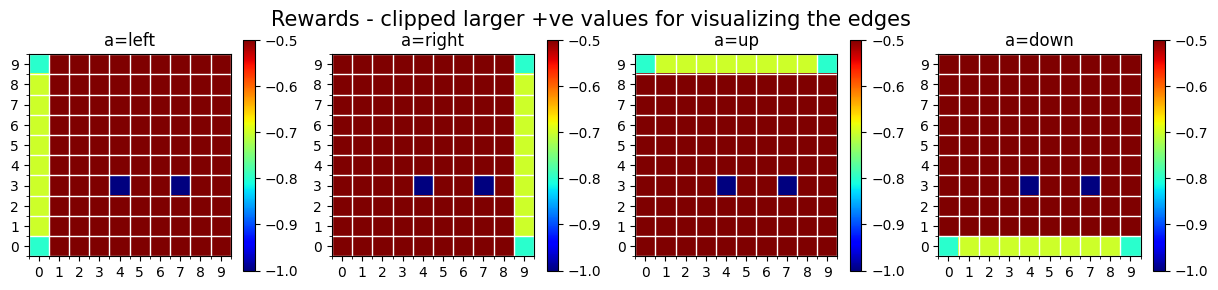

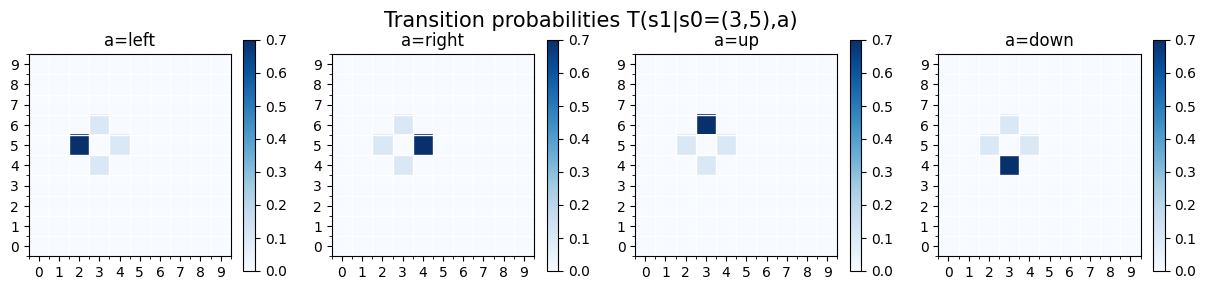

In [ ]:
#Define the MDP
mdp = MDP()
mdp.inbuilt_init(mdp_dict=createGrid10World())

#Plot states
pl.figure(figsize=(3,3))
mdp.gridPlot(ax=pl.gca(), im=mdp.S.reshape((10,10)), title='States', cmap='Greys')

#Plot rewards
pl.figure(figsize=(15,3))
pl.suptitle('Rewards', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=mdp.R[:,a].reshape((10,10)), title='a='+mdp.A[a], cmap='jet')
pl.show()

#Plot rewards
pl.figure(figsize=(15,3))
pl.suptitle('Rewards - clipped larger +ve values for visualizing the edges', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=np.clip(mdp.R[:,a].reshape((10,10)), -1, -0.5), title='a='+mdp.A[a], cmap='jet')
pl.show()

#Plot rewards
s0_x, s0_y = 3, 5
s0 = mdp.xy2s(s0_x, s0_y)
pl.figure(figsize=(15,3))
pl.suptitle('Transition probabilities T(s1|s0=({},{}),a)'.format(s0_x, s0_y), fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    mdp.gridPlot(ax=pl.gca(), im=mdp.T[s0,a,:].reshape((10,10)), title='a='+mdp.A[a], cmap='Blues')
pl.show()

In [ ]:
#An interactive plot of transition probabilities
def f(s0_x, s0_y, action):
    a = mdp.A.index(action)
    s0 = mdp.xy2s(int(s0_x), int(s0_y))
    pl.figure(figsize=(6,6))
    title = 'Transition probabilities T(s1|s0=({},{}),a={})'.format(int(s0_x),int(s0_y),action)
    mdp.gridPlot(ax=pl.gca(), im=mdp.T[s0,a,:].reshape((10,10)), title=title, cmap='Blues')
    pl.show()

interactive_plot = interactive(f, s0_x='4', s0_y='5', action=widgets.ToggleButtons(options=['left', 'right', 'up', 'down']))
interactive_plot

interactive(children=(Text(value='4', description='s0_x'), Text(value='5', description='s0_y'), ToggleButtons(…

### 1. Policy evaluation

Computing the utility, U.

$U^\pi_k(s) = R(s, \pi(s)) + \gamma \sum_{s'} T(s' \mid s, \pi(s))U^\pi_{k-1}(s')$

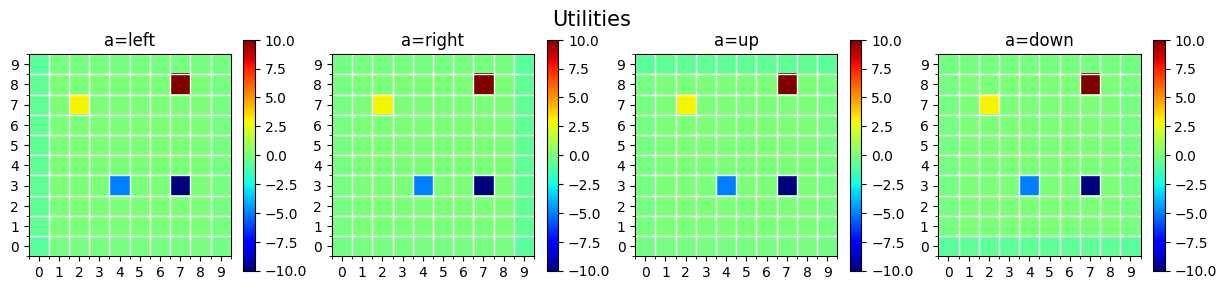

In [ ]:
def iterativePolicyEvaluation(mdp, policy, numIterations=10):
    U = np.zeros(len(mdp.S))
    U_old = copy.copy(U)
    for t in range(numIterations):
        #type your code here
        for s in mdp.S:
            # Determine action for this state
            a = policy if isinstance(policy, (int, np.integer)) else policy[s]

            # Bellman expectation update
            U[s] = mdp.R[s, a] + mdp.discount * sum(
                mdp.T[s, a, s_next] * U_old[s_next] for s_next in mdp.S
            )
    return U

numIterations = 5
pl.figure(figsize=(15,3))
pl.suptitle('Utilities', fontsize=15)
for a in range(4):
    pl.subplot(1,4,a+1)
    U = iterativePolicyEvaluation(mdp=mdp, policy=a, numIterations=numIterations)
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='a='+mdp.A[a], cmap='jet')
pl.show()
#print(np.round(U.reshape(10,10),3))

In [ ]:
def f(action, numIter=1):
    U = iterativePolicyEvaluation(mdp, policy=mdp.A.index(action), numIterations=numIter)
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
    pl.show()

interactive_plot = interactive(f, action=widgets.ToggleButtons(options=['left', 'right', 'up', 'down']),
                               numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(ToggleButtons(description='action', options=('left', 'right', 'up', 'down'), value='left…

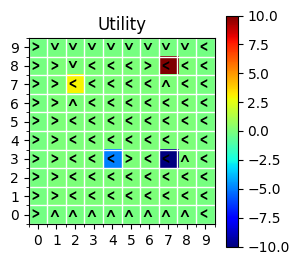

In [ ]:
#Value iteration
def valueIteration(mdp, numIterations=1):
    U = np.zeros(len(mdp.S))
    U_old = copy.copy(U)
    for t in range(numIterations):
        for s in mdp.S:
            # Compute the expected utility for all actions
            action_values = []
            for a in range(len(mdp.A)):
                value = mdp.R[s, a] + mdp.discount * sum(
                    mdp.T[s, a, s_next] * U_old[s_next] for s_next in mdp.S
                )
                action_values.append(value)
            # Take the maximum over actions
            U[s] = max(action_values)
    return U

def policyExtration(mdp, U):
    policy = np.zeros(len(mdp.S))
    #type your code here
    for s in mdp.S:
        action_values = []
        for a in range(len(mdp.A)):
            value = mdp.R[s, a] + mdp.discount * sum(
                mdp.T[s, a, s_next] * U[s_next] for s_next in mdp.S
            )
            action_values.append(value)
        # Pick the action with maximum value
        policy[s] = np.argmax(action_values)
    return policy

U = valueIteration(mdp, numIterations=2)
policy = policyExtration(mdp, U=U)
pl.figure(figsize=(3,3))
mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
for s in range(100):
    x, y = mdp.s2xy(s)
    if policy[s] == 0:
        m='\u02C2'
    elif policy[s] == 1:
        m='\u02C3'
    elif policy[s] == 2:
        m='\u02C4'
    elif policy[s] == 3:
        m='\u02C5'
    pl.text(x-0.5,y-1,m,color='k',size=20)
pl.show()

In [ ]:
def f(numIter=1):
    start_time = timeit.default_timer()
    U = valueIteration(mdp, numIterations=numIter)
    policy = policyExtration(mdp, U=U)
    elapsed = timeit.default_timer() - start_time
    print('time=', np.round(elapsed*1000,2))
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=U.reshape(10,10), title='Utility', cmap='jet')
    for s in range(100):
        x, y = mdp.s2xy(s)
        if policy[s] == 0:
            m='\u02C2'
        elif policy[s] == 1:
            m='\u02C3'
        elif policy[s] == 2:
            m='\u02C4'
        elif policy[s] == 3:
            m='\u02C5'
        pl.text(x-0.5,y-1,m,color='k',size=20)
    pl.show()

interactive_plot = interactive(f, numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(IntSlider(value=0, description='numIter', max=20), Output()), _dom_classes=('widget-inte…

### 2. Policy iteration

Policy evaluation can be used in policy iteration:
1. Given the current policy, compute U
2. Using U, compute a new policy

In [ ]:
def policyIteration(mdp, numIterations=1, evalIterations=5):
    U_pi_k = np.zeros(len(mdp.S)) #initial values
    pi_k = np.random.randint(low=0,high=4,size=len(mdp.S),dtype=int) #initial policy
    pi_kp1 = copy.copy(pi_k)
    for t in range(numIterations):
        #Policy evaluation: compute U_pi_k
          #type your code here
          for _ in range(evalIterations):
            U_old = U_pi_k.copy()
            for s in mdp.S:
                a = pi_k[s]  # current policy action
                U_pi_k[s] = mdp.R[s, a] + mdp.discount * sum(
                    mdp.T[s, a, s_next] * U_old[s_next] for s_next in mdp.S
                )
        #Policy improvement
          #type your code here
          for s in mdp.S:
            action_values = []
            for a in range(len(mdp.A)):
                value = mdp.R[s, a] + mdp.discount * sum(
                    mdp.T[s, a, s_next] * U_pi_k[s_next] for s_next in mdp.S
                )
                action_values.append(value)
            pi_kp1[s] = np.argmax(action_values)
    return U_pi_k, pi_kp1

U_pi_k, pi_kp1 = policyIteration(mdp, numIterations=2)

In [ ]:
def f(numIter=1):
    start_time = timeit.default_timer()
    # code you want to evaluate
    value, policy = policyIteration(mdp, numIterations=numIter)
    elapsed = timeit.default_timer() - start_time
    print('time=', np.round(elapsed*1000,2))
    pl.figure(figsize=(3,3))
    mdp.gridPlot(ax=pl.gca(), im=value.reshape(10,10), title='Utility', cmap='jet')
    for s in range(100):
        x, y = mdp.s2xy(s)
        if policy[s] == 0:
            m='\u02C2'
        elif policy[s] == 1:
            m='\u02C3'
        elif policy[s] == 2:
            m='\u02C4'
        elif policy[s] == 3:
            m='\u02C5'
        pl.text(x-0.5,y-1,m,color='k',size=20)
    pl.show()

interactive_plot = interactive(f, numIter=widgets.IntSlider(min=0, max=20, step=1, value=0))
interactive_plot

interactive(children=(IntSlider(value=0, description='numIter', max=20), Output()), _dom_classes=('widget-inte…

**Tasks Screen Shots**

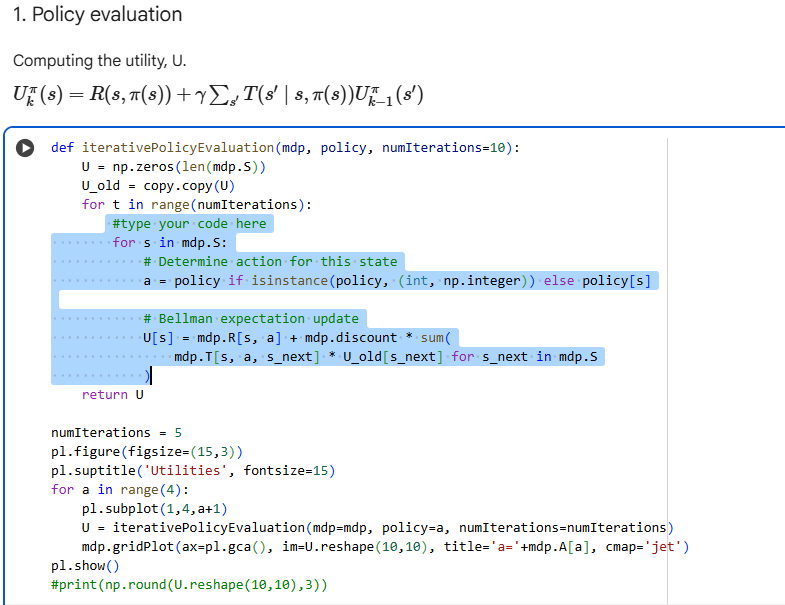

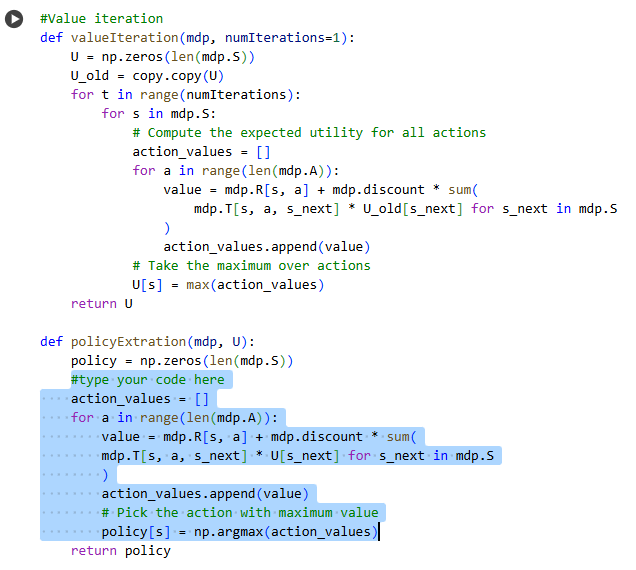

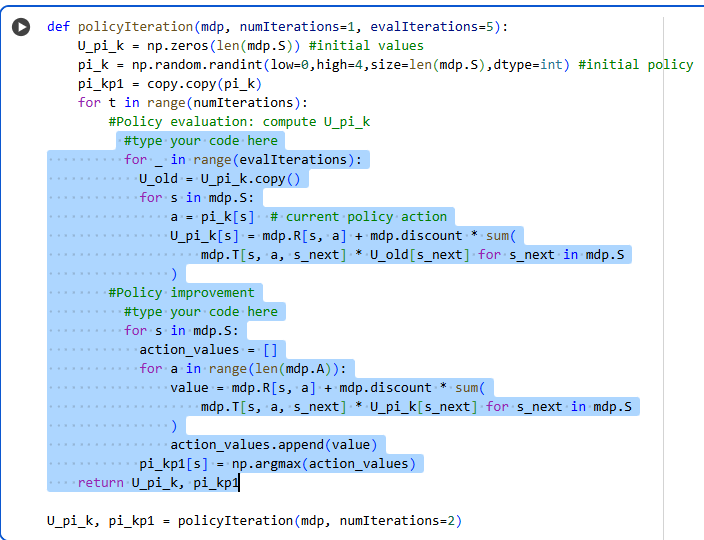

 2.Briefly explain the difference between Model-Based and Model-Free algorithms.
 Model-Based algorithms:
These methods first try to learn or use a model of the environment (i.e., how states change and what rewards follow actions). Once the model is known, they can plan by simulating outcomes before acting.
Model-Free algorithms:
These do not learn the environment’s model. Instead, they directly learn from experience which actions are good or bad by updating value estimates or policies. They rely only on trial-and-error interaction.
Example: Q-Learning, SARSA, Policy Gradient methods.

Question1

----task1---

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import gym
import random

class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim)
        )
    def forward(self, x):
        return self.net(x)

env = gym.make("CartPole-v1")
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
q_net = QNetwork(state_dim, action_dim)
print(q_net)


QNetwork(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


----task2----

In [ ]:
def epsilon_greedy_action(qnet, state, eps, env):
    if np.random.rand() < eps:
        return env.action_space.sample()       # explore
    state = torch.FloatTensor(state).unsqueeze(0)
    with torch.no_grad():
        q_values = qnet(state)
    return q_values.argmax().item()            # exploit


---task3---

In [ ]:
def train_dqn(env, qnet, eps=0.1, episodes=300, gamma=0.99, lr=1e-3):
    optimizer = optim.Adam(qnet.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    rewards = []

    for ep in range(episodes):
        s = env.reset()
        done = False
        total_reward = 0

        while not done:
            a = epsilon_greedy_action(qnet, s, eps, env)
            s2, r, done, _ = env.step(a)

            s_t = torch.FloatTensor(s).unsqueeze(0)
            s2_t = torch.FloatTensor(s2).unsqueeze(0)

            q_pred = qnet(s_t)[0, a]
            with torch.no_grad():
                target = r + gamma * (0 if done else qnet(s2_t).max().item())

            loss = loss_fn(q_pred, torch.tensor(target))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            s = s2
            total_reward += r

        rewards.append(total_reward)
        if (ep + 1) % 20 == 0:
            print(f"Episode {ep+1}, Avg Reward: {np.mean(rewards[-20:]):.2f}")

    return rewards



Training with ε = 0.1
Episode 20, Avg Reward: 10.05
Episode 40, Avg Reward: 10.80
Episode 60, Avg Reward: 9.75
Episode 80, Avg Reward: 12.60
Episode 100, Avg Reward: 16.75
Episode 120, Avg Reward: 19.20
Episode 140, Avg Reward: 34.65
Episode 160, Avg Reward: 37.30
Episode 180, Avg Reward: 43.50
Episode 200, Avg Reward: 41.80

Training with ε = 0.5
Episode 20, Avg Reward: 15.05
Episode 40, Avg Reward: 14.60
Episode 60, Avg Reward: 19.75
Episode 80, Avg Reward: 29.25
Episode 100, Avg Reward: 35.60
Episode 120, Avg Reward: 44.40
Episode 140, Avg Reward: 32.35
Episode 160, Avg Reward: 56.05
Episode 180, Avg Reward: 56.30
Episode 200, Avg Reward: 56.45

Training with ε = 0.9
Episode 20, Avg Reward: 21.80
Episode 40, Avg Reward: 18.65
Episode 60, Avg Reward: 20.35
Episode 80, Avg Reward: 20.60
Episode 100, Avg Reward: 28.05
Episode 120, Avg Reward: 28.45
Episode 140, Avg Reward: 23.50
Episode 160, Avg Reward: 28.05
Episode 180, Avg Reward: 26.75
Episode 200, Avg Reward: 27.80


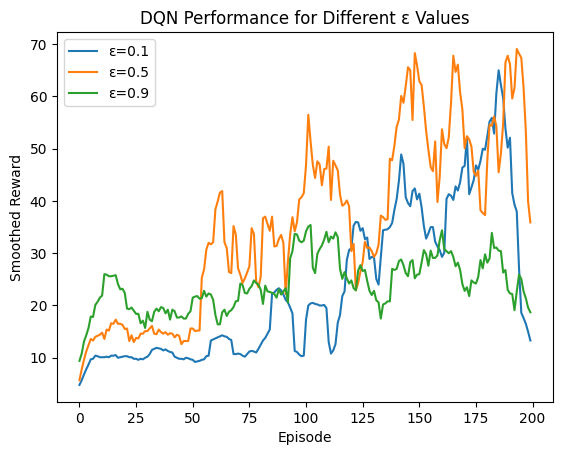

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epsilons = [0.1, 0.5, 0.9]
results = {}

for eps in epsilons:
    print(f"\nTraining with ε = {eps}")
    qnet = QNetwork(state_dim, action_dim)
    rewards = train_dqn(env, qnet, eps=eps, episodes=200)
    results[eps] = rewards

for eps, r in results.items():
    plt.plot(np.convolve(r, np.ones(10)/10, mode='same'), label=f"ε={eps}")
plt.xlabel("Episode")
plt.ylabel("Smoothed Reward")
plt.title("DQN Performance for Different ε Values")
plt.legend()
plt.show()


Question 2

task1

In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import gymnasium as gym
import matplotlib.pyplot as plt
from collections import deque

# Define Q-network (you can train this later)
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(QNetwork, self).__init__()
        self.fc1 = nn.Linear(state_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.out = nn.Linear(128, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)

# ✅ Replace this line:
# env = gym.make("LunarLander-v3")
# 🚀 With this (no Box2D needed):
env = gym.make("CartPole-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

q_net = QNetwork(state_dim, action_dim)
target_net = QNetwork(state_dim, action_dim)
target_net.load_state_dict(q_net.state_dict())

print("✅ Environment loaded successfully!")
print("State dimension:", state_dim)
print("Action dimension:", action_dim)


✅ Environment loaded successfully!
State dimension: 4
Action dimension: 2


task2

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity=100000):
        self.buffer = deque(maxlen=capacity)
    def push(self, s,a,r,s2,d):
        self.buffer.append((s,a,r,s2,d))
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        s,a,r,s2,d = map(np.array, zip(*batch))
        return s,a,r,s2,d
    def __len__(self):
        return len(self.buffer)


task3

In [ ]:
def get_epsilon(episode, start_eps=1.0, end_eps=0.01, decay_episodes=700):
    eps = end_eps + (start_eps - end_eps) * max(0, (decay_episodes - episode)/decay_episodes)
    return eps


task4

In [ ]:
def train_lunar_dqn(episodes=300,
                    batch_size=64,
                    gamma=0.99,
                    lr=1e-3,
                    target_update_freq=500,
                    min_buffer=1000):
    optimizer = optim.Adam(q_net.parameters(), lr=lr)
    buffer = ReplayBuffer()
    rewards, eps_history, loss_history = [], [], []
    total_steps = 0

    for ep in range(episodes):
        s, _ = env.reset()                      # gymnasium reset -> (obs, info)
        done = False
        ep_reward = 0
        eps = get_epsilon(ep)

        while not done:
            a = epsilon_greedy_action(q_net, s, eps, env)
            s2, r, terminated, truncated, _ = env.step(a)   # gymnasium step
            done = terminated or truncated

            buffer.push(s, a, r, s2, done)
            s = s2
            ep_reward += r
            total_steps += 1

            if len(buffer) > min_buffer:
                sb, ab, rb, s2b, db = buffer.sample(batch_size)
                sb = torch.FloatTensor(sb)
                ab = torch.LongTensor(ab).unsqueeze(1)
                rb = torch.FloatTensor(rb).unsqueeze(1)
                s2b = torch.FloatTensor(s2b)
                db = torch.FloatTensor(db).unsqueeze(1)

                q_values = q_net(sb).gather(1, ab)
                with torch.no_grad():
                    target_q = target_net(s2b).max(1)[0].unsqueeze(1)
                    y = rb + gamma * (1 - db) * target_q

                loss = F.mse_loss(q_values, y)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                loss_history.append(loss.item())

            if total_steps % target_update_freq == 0:
                target_net.load_state_dict(q_net.state_dict())

        rewards.append(ep_reward)
        eps_history.append(eps)

        if (ep + 1) % 10 == 0:
            print(f"Episode {ep+1}, Avg Reward(10 ep): {np.mean(rewards[-10:]):.2f}, Eps: {eps:.3f}")

    return rewards, eps_history, loss_history


task6

Episode 10, Avg Reward(10 ep): 22.00, Eps: 0.987
Episode 20, Avg Reward(10 ep): 17.90, Eps: 0.973
Episode 30, Avg Reward(10 ep): 22.50, Eps: 0.959
Episode 40, Avg Reward(10 ep): 19.10, Eps: 0.945
Episode 50, Avg Reward(10 ep): 21.60, Eps: 0.931
Episode 60, Avg Reward(10 ep): 22.20, Eps: 0.917
Episode 70, Avg Reward(10 ep): 22.00, Eps: 0.902
Episode 80, Avg Reward(10 ep): 17.80, Eps: 0.888
Episode 90, Avg Reward(10 ep): 22.70, Eps: 0.874
Episode 100, Avg Reward(10 ep): 21.10, Eps: 0.860
Episode 110, Avg Reward(10 ep): 20.30, Eps: 0.846
Episode 120, Avg Reward(10 ep): 22.20, Eps: 0.832
Episode 130, Avg Reward(10 ep): 26.40, Eps: 0.818
Episode 140, Avg Reward(10 ep): 27.40, Eps: 0.803
Episode 150, Avg Reward(10 ep): 30.70, Eps: 0.789
Episode 160, Avg Reward(10 ep): 37.50, Eps: 0.775
Episode 170, Avg Reward(10 ep): 24.20, Eps: 0.761
Episode 180, Avg Reward(10 ep): 41.70, Eps: 0.747
Episode 190, Avg Reward(10 ep): 39.70, Eps: 0.733
Episode 200, Avg Reward(10 ep): 33.40, Eps: 0.719
Episode 2

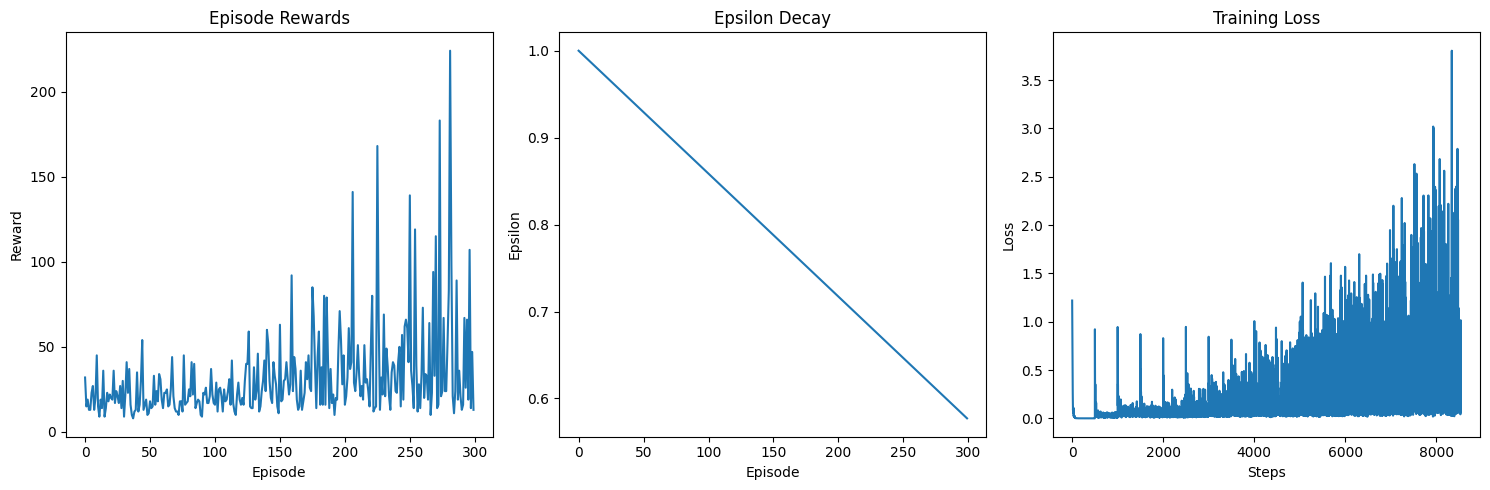

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
import random
import numpy as np

# --- Run the training ---
rewards, eps_history, loss_history = train_lunar_dqn(episodes=300)

# --- 📊 Plot charts ---
plt.figure(figsize=(15, 5))

# Reward chart
plt.subplot(1, 3, 1)
plt.plot(rewards)
plt.title("Episode Rewards")
plt.xlabel("Episode")
plt.ylabel("Reward")

# Epsilon decay
plt.subplot(1, 3, 2)
plt.plot(eps_history)
plt.title("Epsilon Decay")
plt.xlabel("Episode")
plt.ylabel("Epsilon")

# Loss curve
plt.subplot(1, 3, 3)
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Steps")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()
